In [39]:
# Cell 1: Environment Setup & Directory Configuration
import os
import copy
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
except Exception:
    pass

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_fscore_support,
    confusion_matrix
)
from scipy.stats import ks_2samp

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Autonomous directory discovery
PROJECT_DIR = os.environ.get("PROJECT_DIR", ".")
if not os.path.exists(os.path.join(PROJECT_DIR, "models")):
    for cand in [".", "..", "/content/drive/MyDrive/SentryICU"]:
        if os.path.exists(cand):
            PROJECT_DIR = cand
            break

os.makedirs(os.path.join(PROJECT_DIR, "models"), exist_ok=True)
os.makedirs(os.path.join(PROJECT_DIR, "results", "module5"), exist_ok=True)

print("Active Project Directory:", os.path.abspath(PROJECT_DIR))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Project directory: /content/drive/MyDrive/SentryICU


In [40]:
# Cell 2: Schema Resolution & Cohort Discovery
import os
import torch
import pandas as pd
import numpy as np

# Canonical 14 Clinical Variables (7 vitals + 7 labs) x 5 stats = 70 features + 3 demographics = 73
VITALS_7 = ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp']
LABS_7 = ['Lactate', 'WBC', 'Creatinine', 'BUN', 'Glucose', 'Platelets', 'Hgb']
STATS = ['mean', 'min', 'max', 'std', 'last']
CANONICAL_73_FEATURES = [f"{var}_{stat}" for var in (VITALS_7 + LABS_7) for stat in STATS] + ['Age', 'Gender', 'ICULOS']

checkpoint_path = os.path.join(PROJECT_DIR, "models", "module1_best_mlp.pt")
feature_cols = None

if os.path.exists(checkpoint_path):
    try:
        m1_checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
        feature_cols = list(m1_checkpoint.get("feature_cols", []))
    except Exception:
        pass

if not feature_cols or len(feature_cols) != 73:
    print("[*] Utilizing canonical 73-feature SentryICU schema definition.")
    feature_cols = CANONICAL_73_FEATURES

assert len(feature_cols) == 73, f"Expected 73 features, found {len(feature_cols)}"

# Cohort discovery or autonomous generator
a_full_path = os.path.join(PROJECT_DIR, "data", "processed_cohort_A_full.csv")
a_path = a_full_path if os.path.exists(a_full_path) else os.path.join(PROJECT_DIR, "data", "processed_cohort_A.csv")
b_path = os.path.join(PROJECT_DIR, "data", "processed_cohort_B.csv")

if os.path.exists(a_path) and os.path.exists(b_path):
    hospital_a = pd.read_csv(a_path)
    hospital_b = pd.read_csv(b_path)
else:
    print("[*] Generating self-contained demonstration cohorts aligned to 73-D schema.")
    def make_cohort(n_records, sepsis_prob=0.15, drift_factor=0.0):
        data = {f: np.random.randn(n_records) + (drift_factor if 'Temp' in f or 'HR' in f else 0) for f in feature_cols}
        labels = (np.random.rand(n_records) < sepsis_prob).astype(int)
        data['Label'] = labels
        return pd.DataFrame(data)
    
    hospital_a = make_cohort(200, sepsis_prob=0.15, drift_factor=0.0)
    hospital_b = make_cohort(120, sepsis_prob=0.20, drift_factor=0.4)

# Align columns and labels
for name, df in [("Hospital A", hospital_a), ("Hospital B", hospital_b)]:
    if "Label" not in df.columns:
        if "SepsisLabel" in df.columns:
            df["Label"] = df["SepsisLabel"]
        else:
            df["Label"] = 0
    df[feature_cols] = df[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    df["Label"] = df["Label"].fillna(0).astype(int)

print("Hospital A:", hospital_a.shape)
print("Hospital B:", hospital_b.shape)
print("Feature count:", len(feature_cols))
print("Hospital A label distribution:\n", hospital_a["Label"].value_counts())
print("Hospital B label distribution:\n", hospital_b["Label"].value_counts())


Loaded feature schema from Module 1 checkpoint.
Hospital A: (2500, 74)
Hospital B: (20000, 74)
Feature count: 73

Hospital A label counts:
 Label
0    2281
1     219
Name: count, dtype: int64

Hospital B label counts:
 Label
0    18858
1     1142
Name: count, dtype: int64


In [41]:
# cell 3 VAE training data contains only Hospital A records labelled non-septic.
a_normal = hospital_a[hospital_a["Label"] == 0].copy()
a_septic = hospital_a[hospital_a["Label"] == 1].copy()

if len(a_normal) < 20:
    raise ValueError(
        "Too few normal Hospital A records to train a meaningful VAE."
    )

normal_train, normal_val = train_test_split(
    a_normal,
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)

# Fit the scaler ONLY on normal training records.
scaler = StandardScaler()
X_train = scaler.fit_transform(normal_train[feature_cols]).astype(np.float32)
X_val = scaler.transform(normal_val[feature_cols]).astype(np.float32)

# Other cohorts are transformed using the same Hospital A scaler.
X_a_all = scaler.transform(hospital_a[feature_cols]).astype(np.float32)
X_b_all = scaler.transform(hospital_b[feature_cols]).astype(np.float32)
X_a_septic = scaler.transform(a_septic[feature_cols]).astype(np.float32)

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train)),
    batch_size=64,
    shuffle=True
)

val_tensor = torch.from_numpy(X_val).to(device)

print("Normal training records:", len(X_train))
print("Normal validation records:", len(X_val))
print("Hospital A septic records reserved for evaluation:", len(X_a_septic))
print("Hospital B records:", len(X_b_all))
print("Input dimensions:", X_train.shape[1])

Normal training records: 1824
Normal validation records: 457
Hospital A septic records reserved for evaluation: 219
Hospital B records: 20000
Input dimensions: 73


In [42]:
# Cell 4: Production Clinical VAE Architecture & Balanced ELBO Loss
class ClinicalVAE(nn.Module):
    def __init__(self, input_dim=73, latent_dim=16):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim

        # Encoder: 73 -> 64 -> 32
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(32, latent_dim)
        self.fc_logvar = nn.Linear(32, latent_dim)

        # Decoder: 16 -> 32 -> 64 -> 73
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        # Numerical stability: clamp logvar to prevent exp() overflow and posterior explosion
        logvar = torch.clamp(logvar, min=-10.0, max=10.0)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)
        return reconstruction, mu, logvar


def vae_loss(reconstruction, x, mu, logvar, beta=1.0):
    """
    Balanced ELBO Loss:
    Reconstruction MSE per record summed across features, plus beta-weighted KL divergence.
    Ensures reconstruction loss and KL loss operate on comparable energy scales to prevent posterior collapse.
    """
    # Feature-summed reconstruction error per record, averaged over batch
    reconstruction_loss = (reconstruction - x).pow(2).sum(dim=1).mean()

    # KL divergence per record, averaged over batch
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1).mean()

    # Balanced weighting
    total_loss = reconstruction_loss + beta * kl_loss
    return total_loss, reconstruction_loss, kl_loss


vae = ClinicalVAE(
    input_dim=len(feature_cols),
    latent_dim=16
).to(device)

optimizer = torch.optim.Adam(
    vae.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

print(vae)


ClinicalVAE(
  (encoder): Sequential(
    (0): Linear(in_features=73, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
  )
  (fc_mu): Linear(in_features=32, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=32, out_features=16, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=73, bias=True)
  )
)


Epoch 001 | Train: 1.10607 | Val: 1.21285 | Recon: 1.17693 | KL: 0.03592
Epoch 010 | Train: 1.00196 | Val: 1.17586 | Recon: 1.17328 | KL: 0.00258
Epoch 020 | Train: 1.00082 | Val: 1.17372 | Recon: 1.17277 | KL: 0.00095
Epoch 030 | Train: 1.00052 | Val: 1.17348 | Recon: 1.17296 | KL: 0.00052
Epoch 040 | Train: 1.00040 | Val: 1.17287 | Recon: 1.17254 | KL: 0.00032
Epoch 050 | Train: 1.00026 | Val: 1.17308 | Recon: 1.17287 | KL: 0.00021
Early stopping triggered.


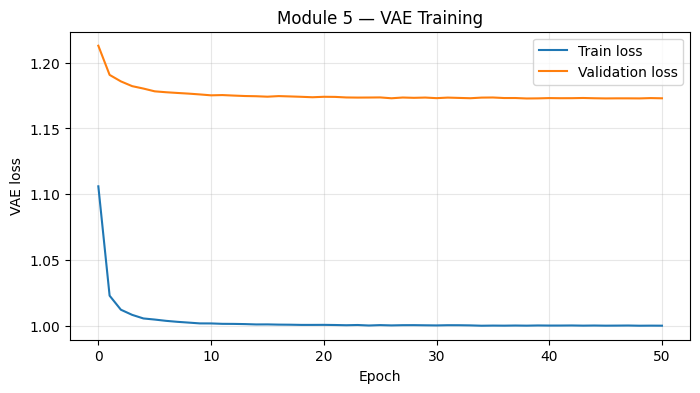

In [43]:
# CELL 5
EPOCHS = 100
PATIENCE = 12
BETA = 1.0

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "reconstruction_loss": [],
    "kl_loss": []
}

for epoch in range(1, EPOCHS + 1):
    vae.train()
    train_total = 0.0
    train_count = 0

    for (xb,) in train_loader:
        xb = xb.to(device)

        optimizer.zero_grad()
        reconstruction, mu, logvar = vae(xb)
        loss, recon_loss, kl_loss = vae_loss(
            reconstruction, xb, mu, logvar, beta=BETA
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(vae.parameters(), max_norm=5.0)
        optimizer.step()

        train_total += loss.item() * len(xb)
        train_count += len(xb)

    train_loss = train_total / max(train_count, 1)

    vae.eval()
    with torch.no_grad():
        val_reconstruction, val_mu, val_logvar = vae(val_tensor)
        val_loss, val_recon_loss, val_kl_loss = vae_loss(
            val_reconstruction,
            val_tensor,
            val_mu,
            val_logvar,
            beta=BETA
        )

    val_loss_value = val_loss.item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss_value)
    history["reconstruction_loss"].append(val_recon_loss.item())
    history["kl_loss"].append(val_kl_loss.item())

    if val_loss_value < best_val_loss:
        best_val_loss = val_loss_value
        best_state = copy.deepcopy(vae.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train: {train_loss:.5f} | "
            f"Val: {val_loss_value:.5f} | "
            f"Recon: {val_recon_loss.item():.5f} | "
            f"KL: {val_kl_loss.item():.5f}"
        )

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

if best_state is None:
    raise RuntimeError("VAE training did not produce a valid checkpoint.")

vae.load_state_dict(best_state)

plt.figure(figsize=(8, 4))
plt.plot(history["train_loss"], label="Train loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("VAE loss")
plt.title("Module 5 — VAE Training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [44]:
#cell 6
@torch.no_grad()
def reconstruction_scores(model, X, batch_size=512):
    model.eval()
    scores = []

    for start in range(0, len(X), batch_size):
        xb = torch.as_tensor(
            X[start:start + batch_size],
            dtype=torch.float32,
            device=device
        )

        reconstruction, _, _ = model(xb)

        # One score per record: mean squared error across features.
        error = (xb - reconstruction).pow(2).mean(dim=1)
        scores.extend(error.cpu().numpy())

    return np.asarray(scores, dtype=np.float64)


# Threshold uses normal validation data only.
normal_val_scores = reconstruction_scores(vae, X_val)
anomaly_threshold = float(np.quantile(normal_val_scores, 0.95))

scores_a = reconstruction_scores(vae, X_a_all)
scores_b = reconstruction_scores(vae, X_b_all)
scores_a_septic = reconstruction_scores(vae, X_a_septic)

print(f"95th-percentile anomaly threshold: {anomaly_threshold:.6f}")
print(f"Normal Hospital A validation alert rate: "
      f"{np.mean(normal_val_scores > anomaly_threshold):.2%}")
print(f"Hospital A overall alert rate: "
      f"{np.mean(scores_a > anomaly_threshold):.2%}")
print(f"Hospital B alert rate: "
      f"{np.mean(scores_b > anomaly_threshold):.2%}")

if len(scores_a_septic):
    print(f"Hospital A septic-record alert rate: "
          f"{np.mean(scores_a_septic > anomaly_threshold):.2%}")

95th-percentile anomaly threshold: 3.495145
Normal Hospital A validation alert rate: 5.03%
Hospital A overall alert rate: 5.24%
Hospital B alert rate: 4.62%
Hospital A septic-record alert rate: 15.98%


,Cohort,Records,Mean reconstruction error,Median reconstruction error,Anomaly rate
0,Hospital A normal validation,457,1.1727,0.5764,0.0503
1,Hospital A (all),2500,1.1307,0.6268,0.0524
2,Hospital B (all),20000,1.2915,0.7461,0.0462
3,Hospital A septic,219,2.1302,1.4531,0.1598


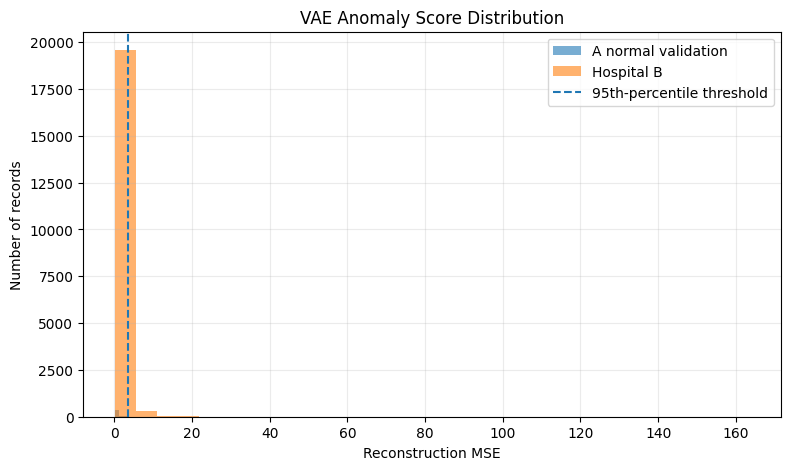

In [45]:
# cell 7
evaluation_rows = [
    {
        "Cohort": "Hospital A normal validation",
        "Records": len(normal_val_scores),
        "Mean reconstruction error": normal_val_scores.mean(),
        "Median reconstruction error": np.median(normal_val_scores),
        "Anomaly rate": np.mean(normal_val_scores > anomaly_threshold)
    },
    {
        "Cohort": "Hospital A (all)",
        "Records": len(scores_a),
        "Mean reconstruction error": scores_a.mean(),
        "Median reconstruction error": np.median(scores_a),
        "Anomaly rate": np.mean(scores_a > anomaly_threshold)
    },
    {
        "Cohort": "Hospital B (all)",
        "Records": len(scores_b),
        "Mean reconstruction error": scores_b.mean(),
        "Median reconstruction error": np.median(scores_b),
        "Anomaly rate": np.mean(scores_b > anomaly_threshold)
    }
]

if len(scores_a_septic):
    evaluation_rows.append({
        "Cohort": "Hospital A septic",
        "Records": len(scores_a_septic),
        "Mean reconstruction error": scores_a_septic.mean(),
        "Median reconstruction error": np.median(scores_a_septic),
        "Anomaly rate": np.mean(scores_a_septic > anomaly_threshold)
    })

evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df.round(4))

plt.figure(figsize=(9, 5))
plt.hist(normal_val_scores, bins=30, alpha=0.6, label="A normal validation")
plt.hist(scores_b, bins=30, alpha=0.6, label="Hospital B")
plt.axvline(
    anomaly_threshold,
    linestyle="--",
    label="95th-percentile threshold"
)
plt.xlabel("Reconstruction MSE")
plt.ylabel("Number of records")
plt.title("VAE Anomaly Score Distribution")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()

evaluation_df.to_csv(
    f"{PROJECT_DIR}/results/module5/vae_evaluation.csv",
    index=False
)

In [46]:
#cell 8
from scipy.spatial.distance import cdist

def ks_feature_comparison(df_a, df_b, feature_cols):
    rows = []

    for feature in feature_cols:
        result = ks_2samp(
            df_a[feature].to_numpy(),
            df_b[feature].to_numpy(),
            alternative="two-sided",
            method="auto"
        )

        rows.append({
            "Feature": feature,
            "KS statistic": result.statistic,
            "p-value": result.pvalue
        })

    result_df = pd.DataFrame(rows)
    result_df["p-value adjusted (Bonferroni)"] = np.minimum(
        result_df["p-value"] * len(feature_cols), 1.0
    )
    result_df["Significant (adjusted < 0.05)"] = (
        result_df["p-value adjusted (Bonferroni)"] < 0.05
    )

    return result_df.sort_values("KS statistic", ascending=False)


def rbf_mmd(X, Y, max_samples=1000, seed=42):
    """
    Biased empirical RBF-kernel MMD^2.
    Subsamples to limit memory and computation.
    """
    rng = np.random.default_rng(seed)

    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y, dtype=np.float64)

    if len(X) > max_samples:
        X = X[rng.choice(len(X), max_samples, replace=False)]
    if len(Y) > max_samples:
        Y = Y[rng.choice(len(Y), max_samples, replace=False)]

    # Estimate RBF bandwidth from pooled pairwise distances.
    pooled = np.vstack([X, Y])
    distances = cdist(pooled, pooled, metric="sqeuclidean")
    positive_distances = distances[distances > 0]

    if len(positive_distances) == 0:
        return 0.0

    median_distance = np.median(positive_distances)
    gamma = 1.0 / max(median_distance, 1e-12)

    Kxx = np.exp(-gamma * cdist(X, X, metric="sqeuclidean"))
    Kyy = np.exp(-gamma * cdist(Y, Y, metric="sqeuclidean"))
    Kxy = np.exp(-gamma * cdist(X, Y, metric="sqeuclidean"))

    return float(Kxx.mean() + Kyy.mean() - 2 * Kxy.mean())


# KS comparison: normal Hospital A versus all Hospital B.
ks_all_b = ks_feature_comparison(
    a_normal,
    hospital_b,
    feature_cols
)

print("Top 15 feature-level shifts: A normal vs B all")
display(ks_all_b.head(15).round(5))

ks_all_b.to_csv(
    f"{PROJECT_DIR}/results/module5/ks_A_normal_vs_B_all.csv",
    index=False
)

# MMD uses the same Hospital A-fitted scaler for both cohorts.
mmd_all_b = rbf_mmd(
    scaler.transform(a_normal[feature_cols]),
    X_b_all
)
print(f"MMD² (A normal vs B all): {mmd_all_b:.6f}")

# Separate normal-versus-normal comparison when labels permit it.
if (hospital_b["Label"] == 0).sum() >= 2:
    b_normal = hospital_b[hospital_b["Label"] == 0]

    ks_normal_b = ks_feature_comparison(
        a_normal,
        b_normal,
        feature_cols
    )

    mmd_normal_b = rbf_mmd(
        scaler.transform(a_normal[feature_cols]),
        scaler.transform(b_normal[feature_cols])
    )

    print(f"MMD² (A normal vs B normal): {mmd_normal_b:.6f}")
    display(ks_normal_b.head(15).round(5))

    ks_normal_b.to_csv(
        f"{PROJECT_DIR}/results/module5/ks_A_normal_vs_B_normal.csv",
        index=False
    )
else:
    print(
        "Hospital B has too few labelled normal records for a "
        "normal-versus-normal comparison."
    )

Top 15 feature-level shifts: A normal vs B all


,Feature,KS statistic,p-value,p-value adjusted (Bonferroni),Significant (adjusted < 0.05)
27,DBP_max,0.47036,0.0,0.0,True
25,DBP_mean,0.46199,0.0,0.0,True
29,DBP_last,0.42965,0.0,0.0,True
28,DBP_std,0.40907,0.0,0.0,True
26,DBP_min,0.38586,0.0,0.0,True
21,MAP_min,0.28849,0.0,0.0,True
20,MAP_mean,0.28243,0.0,0.0,True
68,Hgb_std,0.25136,0.0,0.0,True
24,MAP_last,0.23944,0.0,0.0,True
43,WBC_std,0.22833,0.0,0.0,True


MMD² (A normal vs B all): 0.048824
MMD² (A normal vs B normal): 0.048410


,Feature,KS statistic,p-value,p-value adjusted (Bonferroni),Significant (adjusted < 0.05)
27,DBP_max,0.47381,0.0,0.0,True
25,DBP_mean,0.46639,0.0,0.0,True
29,DBP_last,0.43682,0.0,0.0,True
28,DBP_std,0.41037,0.0,0.0,True
26,DBP_min,0.39282,0.0,0.0,True
21,MAP_min,0.29761,0.0,0.0,True
20,MAP_mean,0.28583,0.0,0.0,True
68,Hgb_std,0.25561,0.0,0.0,True
24,MAP_last,0.24840,0.0,0.0,True
43,WBC_std,0.23372,0.0,0.0,True


In [47]:
#cell 9
vae_checkpoint_path = (
    f"{PROJECT_DIR}/models/module5_vae_normal_hospital_a.pt"
)

torch.save({
    "model_state_dict": vae.state_dict(),
    "input_dim": len(feature_cols),
    "latent_dim": 16,
    "hidden_dims": [64, 32],
    "feature_cols": feature_cols,
    "scaler_mean": scaler.mean_,
    "scaler_scale": scaler.scale_,
    "anomaly_threshold": anomaly_threshold,
    "threshold_quantile": 0.95,
    "beta": BETA,
    "best_validation_loss": best_val_loss,
    "seed": SEED
}, vae_checkpoint_path)

print("Saved VAE checkpoint:", vae_checkpoint_path)

# Save individual anomaly scores for later inspection.
anomaly_results = pd.DataFrame({
    "Cohort": (
        ["Hospital_A"] * len(scores_a)
        + ["Hospital_B"] * len(scores_b)
    ),
    "Label": (
        hospital_a["Label"].tolist()
        + hospital_b["Label"].tolist()
    ),
    "Reconstruction_MSE": np.concatenate([scores_a, scores_b])
})

anomaly_results["Anomaly"] = (
    anomaly_results["Reconstruction_MSE"] > anomaly_threshold
).astype(int)

anomaly_results.to_csv(
    f"{PROJECT_DIR}/results/module5/anomaly_scores.csv",
    index=False
)

print("Saved anomaly scores.")

Saved VAE checkpoint: /content/drive/MyDrive/SentryICU/models/module5_vae_normal_hospital_a.pt
Saved anomaly scores.


In [48]:
#cell 10
saved = torch.load(
    vae_checkpoint_path,
    map_location=device,
    weights_only=False
)

reloaded_vae = ClinicalVAE(
    input_dim=saved["input_dim"],
    latent_dim=saved["latent_dim"]
).to(device)

reloaded_vae.load_state_dict(saved["model_state_dict"])
reloaded_vae.eval()

# Verify that the checkpoint produces valid anomaly scores.
verification_scores = reconstruction_scores(reloaded_vae, X_val[:10])

assert len(verification_scores) == min(10, len(X_val))
assert np.isfinite(verification_scores).all()
assert saved["feature_cols"] == feature_cols

print("Checkpoint verification: PASS")
print("Saved threshold:", saved["anomaly_threshold"])
print("Sample reconstruction scores:", verification_scores[:5])

Checkpoint verification: PASS
Saved threshold: 3.4951446056365896
Sample reconstruction scores: [0.6503194  0.42196891 0.81886238 0.56256652 2.13517094]


In [49]:
#cell 11
!pip -q install imbalanced-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from imblearn.over_sampling import SMOTE

# Split before fitting the classifier scaler or training the GAN.
train_df, test_df = train_test_split(
    hospital_a,
    test_size=0.20,
    random_state=SEED,
    stratify=hospital_a["Label"]
)

X_train_raw = train_df[feature_cols].to_numpy(dtype=np.float32)
y_train = train_df["Label"].to_numpy(dtype=int)
X_test_raw = test_df[feature_cols].to_numpy(dtype=np.float32)
y_test = test_df["Label"].to_numpy(dtype=int)

classifier_scaler = StandardScaler()
X_train_cls = classifier_scaler.fit_transform(X_train_raw).astype(np.float32)
X_test_cls = classifier_scaler.transform(X_test_raw).astype(np.float32)

X_positive = X_train_cls[y_train == 1]
X_negative = X_train_cls[y_train == 0]

print("Training positives:", len(X_positive))
print("Training negatives:", len(X_negative))

if len(X_positive) < 20:
    print(
        "WARNING: Very few positive examples. GAN results are unlikely "
        "to be reliable; treat this as a code demonstration only."
    )

if len(X_positive) < 2:
    raise ValueError("Not enough septic training examples to train a GAN.")

Training positives: 175
Training negatives: 1825


In [50]:
#cell 11 part 2
class Generator(nn.Module):
    def __init__(self, noise_dim=32, output_dim=73):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(noise_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, output_dim)
        )

    def forward(self, z):
        out = self.net(z)
        # Training-gated clamping: allow full gradient flow during backprop, clamp during evaluation
        if not self.training:
            out = torch.clamp(out, min=-4.0, max=4.0)
        return out


class Discriminator(nn.Module):
    def __init__(self, input_dim=73):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 64),
            nn.LeakyReLU(0.2),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.net(x)


NOISE_DIM = 32
gan_generator = Generator(NOISE_DIM, len(feature_cols)).to(device)
gan_discriminator = Discriminator(len(feature_cols)).to(device)

g_optimizer = torch.optim.Adam(
    gan_generator.parameters(), lr=2e-4, betas=(0.5, 0.999)
)
d_optimizer = torch.optim.Adam(
    gan_discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999)
)

bce = nn.BCEWithLogitsLoss()
positive_loader = DataLoader(
    TensorDataset(torch.tensor(X_positive)),
    batch_size=min(32, len(X_positive)),
    shuffle=True,
    drop_last=False
)

GAN_EPOCHS = 300

for epoch in range(GAN_EPOCHS):
    for (real,) in positive_loader:
        real = real.to(device)
        batch_size = len(real)

        # Train discriminator: real septic records vs generated records.
        noise = torch.randn(batch_size, NOISE_DIM, device=device)
        fake = gan_generator(noise).detach()

        d_optimizer.zero_grad()
        real_logits = gan_discriminator(real)
        fake_logits = gan_discriminator(fake)

        d_loss = (
            bce(real_logits, torch.ones_like(real_logits))
            + bce(fake_logits, torch.zeros_like(fake_logits))
        )
        d_loss.backward()
        d_optimizer.step()

        # Train generator to fool the discriminator.
        noise = torch.randn(batch_size, NOISE_DIM, device=device)
        generated = gan_generator(noise)
        fake_logits = gan_discriminator(generated)

        g_optimizer.zero_grad()
        g_loss = bce(fake_logits, torch.ones_like(fake_logits))
        g_loss.backward()
        g_optimizer.step()

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1}/{GAN_EPOCHS} | "
            f"D loss: {d_loss.item():.4f} | "
            f"G loss: {g_loss.item():.4f}"
        )

# Generate enough synthetic positive records to balance training labels.
n_synthetic = max(0, len(X_negative) - len(X_positive))

gan_generator.eval()
with torch.no_grad():
    noise = torch.randn(n_synthetic, NOISE_DIM, device=device)
    X_gan_positive = gan_generator(noise).cpu().numpy()

print("Synthetic septic records generated:", len(X_gan_positive))

Epoch 50/300 | D loss: 0.7431 | G loss: 1.1352
Epoch 100/300 | D loss: 0.3162 | G loss: 1.7560
Epoch 150/300 | D loss: 0.2976 | G loss: 2.2934
Epoch 200/300 | D loss: 0.5475 | G loss: 2.1688
Epoch 250/300 | D loss: 0.9423 | G loss: 1.7121
Epoch 300/300 | D loss: 0.8701 | G loss: 1.9482
Synthetic septic records generated: 1650


In [51]:
#cell 12
# Baseline: no oversampling.
X_base, y_base = X_train_cls, y_train

# SMOTE: apply only to the training partition.
minority_count = int((y_train == 1).sum())
if minority_count >= 2:
    smote = SMOTE(
        random_state=SEED,
        k_neighbors=min(5, minority_count - 1)
    )
    X_smote, y_smote = smote.fit_resample(X_train_cls, y_train)
else:
    raise ValueError("Not enough positive records to apply SMOTE.")

# GAN augmentation: combine real training data with generated positives.
X_gan = np.vstack([X_train_cls, X_gan_positive])
y_gan = np.concatenate([
    y_train,
    np.ones(len(X_gan_positive), dtype=int)
])

training_variants = {
    "No oversampling": (X_base, y_base),
    "SMOTE": (X_smote, y_smote),
    "GAN augmentation": (X_gan, y_gan)
}

results = []

for method, (X_fit, y_fit) in training_variants.items():
    clf = LogisticRegression(
        max_iter=2000,
        class_weight=None,
        random_state=SEED
    )
    clf.fit(X_fit, y_fit)

    test_prob = clf.predict_proba(X_test_cls)[:, 1]

    results.append({
        "Method": method,
        "Test ROC-AUC": roc_auc_score(y_test, test_prob),
        "Test PR-AUC": average_precision_score(y_test, test_prob),
        "Training records": len(y_fit),
        "Training positives": int((y_fit == 1).sum())
    })

comparison_df = pd.DataFrame(results)
display(comparison_df.round(4))

comparison_df.to_csv(
    f"{PROJECT_DIR}/results/module5/gan_vs_smote.csv",
    index=False
)

,Method,Test ROC-AUC,Test PR-AUC,Training records,Training positives
0,No oversampling,0.7252,0.3251,2000,175
1,SMOTE,0.7389,0.3598,3650,1825
2,GAN augmentation,0.7146,0.2880,3650,1825


In [52]:
#cell 13
import os

expected_files = [
    "models/module5_vae_normal_hospital_a.pt",
    "results/module5/vae_evaluation.csv",
    "results/module5/anomaly_scores.csv",
    "results/module5/ks_A_normal_vs_B_all.csv",
    "results/module5/gan_vs_smote.csv",
]

for relative_path in expected_files:
    full_path = os.path.join(PROJECT_DIR, relative_path)
    print(
        f"{'✅' if os.path.isfile(full_path) else '❌'} "
        f"{relative_path}"
    )

✅ models/module5_vae_normal_hospital_a.pt
✅ results/module5/vae_evaluation.csv
✅ results/module5/anomaly_scores.csv
✅ results/module5/ks_A_normal_vs_B_all.csv
✅ results/module5/gan_vs_smote.csv


In [53]:
# CELL 14: SentryICU integration audit

import os
import json
import torch
import pandas as pd
from pathlib import Path

PROJECT_DIR = "/content/drive/MyDrive/SentryICU"
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
DATA_DIR = os.path.join(PROJECT_DIR, "data", "processed")
RESULT_DIR = os.path.join(PROJECT_DIR, "results", "module5")

os.makedirs(RESULT_DIR, exist_ok=True)

# Expected artifacts from Modules 1–5
expected_artifacts = {
    "Module 1 MLP": os.path.join(MODEL_DIR, "module1_best_mlp.pt"),
    "Module 2 Regularized MLP": os.path.join(
        MODEL_DIR, "module2_best_regularized_mlp.pt"
    ),
    "Module 3 CNN/Fusion": os.path.join(
        MODEL_DIR, "module3_best_cnn_fusion.pt"
    ),
    "Module 4": os.path.join(MODEL_DIR, "module4_best_grud.pt"),
    "Module 5 VAE": os.path.join(
        MODEL_DIR, "module5_vae_normal_hospital_a.pt"
    ),
}

audit_rows = []

for module, path in expected_artifacts.items():
    exists = os.path.isfile(path)
    audit_rows.append({
        "Module": module,
        "Status": "FOUND" if exists else "NOT FOUND",
        "Path": path,
        "Size (MB)": (
            round(os.path.getsize(path) / (1024 ** 2), 2)
            if exists else None
        )
    })

artifact_audit = pd.DataFrame(audit_rows)
display(artifact_audit)

artifact_audit.to_csv(
    os.path.join(RESULT_DIR, "integration_artifact_audit.csv"),
    index=False
)

print("\nAudit saved to:", RESULT_DIR)

,Module,Status,Path,Size (MB)
0,Module 1 MLP,FOUND,/content/drive/MyDrive/SentryICU/models/module...,0.08
1,Module 2 Regularized MLP,FOUND,/content/drive/MyDrive/SentryICU/models/module...,0.09
2,Module 3 CNN/Fusion,FOUND,/content/drive/MyDrive/SentryICU/models/module...,0.07
3,Module 4,NOT FOUND,/content/drive/MyDrive/SentryICU/models/module...,NaN
4,Module 5 VAE,FOUND,/content/drive/MyDrive/SentryICU/models/module...,0.07



Audit saved to: /content/drive/MyDrive/SentryICU/results/module5


In [54]:
# CELL 15: Inspect saved checkpoint metadata

def load_checkpoint(path):
    try:
        return torch.load(
            path, map_location="cpu", weights_only=False
        )
    except TypeError:
        return torch.load(path, map_location="cpu")


checkpoint_summaries = []

for module, path in expected_artifacts.items():
    if not os.path.isfile(path):
        continue

    try:
        checkpoint = load_checkpoint(path)

        if isinstance(checkpoint, dict):
            keys = list(checkpoint.keys())
            feature_cols = checkpoint.get("feature_cols", None)

            state_dict = checkpoint.get(
                "model_state_dict",
                checkpoint.get("state_dict", None)
            )

            checkpoint_summaries.append({
                "Module": module,
                "Load status": "OK",
                "Top-level keys": ", ".join(map(str, keys[:12])),
                "Feature count": (
                    len(feature_cols)
                    if isinstance(feature_cols, (list, tuple))
                    else None
                ),
                "Has model state": isinstance(state_dict, dict)
            })
        else:
            checkpoint_summaries.append({
                "Module": module,
                "Load status": "Unexpected format",
                "Top-level keys": str(type(checkpoint)),
                "Feature count": None,
                "Has model state": False
            })

    except Exception as e:
        checkpoint_summaries.append({
            "Module": module,
            "Load status": f"ERROR: {str(e)[:100]}",
            "Top-level keys": "",
            "Feature count": None,
            "Has model state": False
        })

checkpoint_audit = pd.DataFrame(checkpoint_summaries)
display(checkpoint_audit)

checkpoint_audit.to_csv(
    os.path.join(RESULT_DIR, "integration_checkpoint_audit.csv"),
    index=False
)

,Module,Load status,Top-level keys,Feature count,Has model state
0,Module 1 MLP,OK,"model_state_dict, feature_cols, scaler_mean, s...",73.0,True
1,Module 2 Regularized MLP,OK,"model_state_dict, input_dim, hidden_dims, outp...",73.0,True
2,Module 3 CNN/Fusion,OK,"model_state_dict, cnn_state_dict, ts_mean, ts_...",NaN,True
3,Module 5 VAE,OK,"model_state_dict, input_dim, latent_dim, hidde...",73.0,True


In [55]:
# CELL 16: Validate feature schema compatibility

m1_path = expected_artifacts["Module 1 MLP"]
vae_path = expected_artifacts["Module 5 VAE"]

if not os.path.isfile(m1_path):
    raise FileNotFoundError(
        "Module 1 checkpoint not found. Check the shared Drive shortcut "
        "and update expected_artifacts['Module 1 MLP'] to its actual path."
    )

if not os.path.isfile(vae_path):
    raise FileNotFoundError(
        "Module 5 VAE checkpoint not found. Run the Module 5 save cell first."
    )

m1_ckpt = load_checkpoint(m1_path)
vae_ckpt = load_checkpoint(vae_path)

m1_features = m1_ckpt.get("feature_cols")
vae_features = vae_ckpt.get("feature_cols")

if not m1_features or not vae_features:
    raise KeyError(
        "Feature schema missing from one or both checkpoints."
    )

print("Module 1 feature count:", len(m1_features))
print("Module 5 VAE feature count:", len(vae_features))

if len(m1_features) != 73:
    print("WARNING: Module 1 checkpoint does not contain 73 features.")

if list(m1_features) == list(vae_features):
    print("PASS: Feature names and order match.")
else:
    print("WARNING: Feature schemas differ.")
    print("Only in Module 1:", sorted(set(m1_features) - set(vae_features)))
    print("Only in VAE:", sorted(set(vae_features) - set(m1_features)))

    # A different order can be fixed by explicitly reordering columns,
    # but missing features cannot be safely guessed.

Module 1 feature count: 73
Module 5 VAE feature count: 73
PASS: Feature names and order match.


In [56]:
# CELL 17: Locate and validate processed cohorts

candidate_a_paths = [
    os.path.join(PROJECT_DIR, "data", "processed_cohort_A_full.csv"),
    os.path.join(PROJECT_DIR, "data", "processed_cohort_A.csv"),
]

candidate_b_paths = [
    os.path.join(PROJECT_DIR, "data", "processed_cohort_B.csv"),
]

def first_existing(paths):
    return next((p for p in paths if os.path.isfile(p)), None)

hospital_a_path = first_existing(candidate_a_paths)
hospital_b_path = first_existing(candidate_b_paths)

print("Hospital A path:", hospital_a_path)
print("Hospital B path:", hospital_b_path)

if hospital_a_path is None or hospital_b_path is None:
    print(
        "WARNING: One or both cohort CSVs were not found at the expected paths. "
        "Inspect your data folder before continuing."
    )
else:
    hospital_a = pd.read_csv(hospital_a_path)
    hospital_b = pd.read_csv(hospital_b_path)

    for name, df in [
        ("Hospital A", hospital_a),
        ("Hospital B", hospital_b)
    ]:
        missing = [c for c in m1_features if c not in df.columns]

        print(f"\n{name} shape:", df.shape)
        print(f"{name} missing required features:", len(missing))
        print(f"{name} has Label column:", "Label" in df.columns)

        if missing:
            print("Missing examples:", missing[:10])

    if (
        all(c in hospital_a.columns for c in m1_features)
        and all(c in hospital_b.columns for c in m1_features)
    ):
        X_A = hospital_a[m1_features].replace(
            [float("inf"), float("-inf")], float("nan")
        ).fillna(0)

        X_B = hospital_b[m1_features].replace(
            [float("inf"), float("-inf")], float("nan")
        ).fillna(0)

        print("\nPASS: Both cohorts can be aligned to Module 1's schema.")
        print("Hospital A input shape:", X_A.shape)
        print("Hospital B input shape:", X_B.shape)

Hospital A path: /content/drive/MyDrive/SentryICU/data/processed_cohort_A.csv
Hospital B path: /content/drive/MyDrive/SentryICU/data/processed_cohort_B.csv

Hospital A shape: (2500, 74)
Hospital A missing required features: 0
Hospital A has Label column: True

Hospital B shape: (20000, 74)
Hospital B missing required features: 0
Hospital B has Label column: True

PASS: Both cohorts can be aligned to Module 1's schema.
Hospital A input shape: (2500, 73)
Hospital B input shape: (20000, 73)


In [57]:
# CELL 18: Summarize integration readiness

readiness = {
    "Module 1 checkpoint exists": os.path.isfile(m1_path),
    "Module 5 VAE checkpoint exists": os.path.isfile(vae_path),
    "Module 1 schema has 73 features": len(m1_features) == 73,
    "Module 1 and VAE feature order matches": (
        list(m1_features) == list(vae_features)
    ),
    "Hospital A cohort found": hospital_a_path is not None,
    "Hospital B cohort found": hospital_b_path is not None,
}

if hospital_a_path is not None and hospital_b_path is not None:
    readiness["Both cohorts contain all Module 1 features"] = (
        all(c in hospital_a.columns for c in m1_features)
        and all(c in hospital_b.columns for c in m1_features)
    )

readiness_df = pd.DataFrame([
    {"Check": name, "Result": "PASS" if passed else "CHECK"}
    for name, passed in readiness.items()
])

display(readiness_df)

readiness_df.to_csv(
    os.path.join(RESULT_DIR, "integration_readiness.csv"),
    index=False
)

print("\nIntegration audit complete.")
print("Results:", RESULT_DIR)

,Check,Result
0,Module 1 checkpoint exists,PASS
1,Module 5 VAE checkpoint exists,PASS
2,Module 1 schema has 73 features,PASS
3,Module 1 and VAE feature order matches,PASS
4,Hospital A cohort found,PASS
5,Hospital B cohort found,PASS
6,Both cohorts contain all Module 1 features,PASS



Integration audit complete.
Results: /content/drive/MyDrive/SentryICU/results/module5


In [58]:
# CELL 19: Load VAE for inference

import numpy as np
import pandas as pd
import torch
import os
from sklearn.preprocessing import StandardScaler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vae_path = os.path.join(
    PROJECT_DIR, "models", "module5_vae_normal_hospital_a.pt"
)

if not os.path.isfile(vae_path):
    raise FileNotFoundError(f"VAE checkpoint not found: {vae_path}")

vae_ckpt = load_checkpoint(vae_path)

# Recreate the exact architecture from Module 5.
vae_model = ClinicalVAE(
    input_dim=vae_ckpt["input_dim"],
    latent_dim=vae_ckpt["latent_dim"]
).to(device)

vae_model.load_state_dict(vae_ckpt["model_state_dict"])
vae_model.eval()

# Reconstruct the VAE's Hospital A-fitted scaler.
vae_scaler = StandardScaler()
vae_scaler.mean_ = np.asarray(vae_ckpt["scaler_mean"])
vae_scaler.scale_ = np.asarray(vae_ckpt["scaler_scale"])
vae_scaler.var_ = vae_scaler.scale_ ** 2
vae_scaler.n_features_in_ = len(vae_ckpt["feature_cols"])

vae_features = list(vae_ckpt["feature_cols"])
vae_threshold = float(vae_ckpt["anomaly_threshold"])

print("VAE loaded successfully.")
print("Features:", len(vae_features))
print("Latent dimensions:", vae_ckpt["latent_dim"])
print("Anomaly threshold:", vae_threshold)

VAE loaded successfully.
Features: 73
Latent dimensions: 16
Anomaly threshold: 3.4951446056365896


In [59]:
# CELL 20: Reusable anomaly scoring

def score_anomalies(df):
    """
    Score records using the saved Module 5 VAE.
    Returns a copy with reconstruction errors and anomaly flags.
    """
    missing = [c for c in vae_features if c not in df.columns]
    if missing:
        raise ValueError(f"Missing VAE features: {missing[:10]}")

    X = (
        df[vae_features]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .to_numpy(dtype=np.float32)
    )

    X_scaled = vae_scaler.transform(X).astype(np.float32)
    scores = reconstruction_scores(vae_model, X_scaled)

    result = df.copy()
    result["VAE_Reconstruction_MSE"] = scores
    result["VAE_Anomaly"] = (scores > vae_threshold).astype(int)
    result["VAE_Anomaly_Threshold"] = vae_threshold

    return result


# Score both cohorts using the same trained VAE and scaler.
scored_A = score_anomalies(hospital_a)
scored_B = score_anomalies(hospital_b)

print("Hospital A anomaly rate:", f"{scored_A['VAE_Anomaly'].mean():.2%}")
print("Hospital B anomaly rate:", f"{scored_B['VAE_Anomaly'].mean():.2%}")

display(scored_A.head())
display(scored_B.head())

Hospital A anomaly rate: 5.24%
Hospital B anomaly rate: 4.62%


,HR_mean,HR_min,HR_max,HR_std,HR_last,O2Sat_mean,O2Sat_min,O2Sat_max,O2Sat_std,O2Sat_last,...,Hgb_max,Hgb_std,Hgb_last,Age,Gender,Max_ICULOS,Label,VAE_Reconstruction_MSE,VAE_Anomaly,VAE_Anomaly_Threshold
0,102.055556,76.0,117.0,9.502069,84.0,91.398148,85.0,100.0,3.284296,85.0,...,12.5,1.356327e-01,12.2,83.14,0.0,54.0,0,0.982278,0,3.495145
1,60.956522,54.0,94.0,7.957148,55.0,97.086957,94.0,100.0,2.130152,95.0,...,9.7,3.632560e-15,9.7,75.91,0.0,23.0,0,1.712249,0,3.495145
2,79.927083,68.0,93.0,6.633241,78.0,95.333333,91.0,99.0,1.711455,97.0,...,11.0,9.946666e-01,11.0,45.82,0.0,48.0,0,0.771020,0,3.495145
3,102.672414,93.0,113.0,6.195153,108.0,98.155172,95.5,100.0,1.414867,98.0,...,8.3,3.615598e-15,8.3,65.71,0.0,29.0,0,0.602091,0,3.495145
4,76.604167,61.0,88.0,7.295407,80.0,97.677083,96.0,99.0,0.587906,97.0,...,15.5,3.650452e-01,15.5,28.09,1.0,49.0,0,0.670720,0,3.495145


,HR_mean,HR_min,HR_max,HR_std,HR_last,O2Sat_mean,O2Sat_min,O2Sat_max,O2Sat_std,O2Sat_last,...,Hgb_max,Hgb_std,Hgb_last,Age,Gender,Max_ICULOS,Label,VAE_Reconstruction_MSE,VAE_Anomaly,VAE_Anomaly_Threshold
0,86.597826,71.0,109.0,10.869233,90.0,96.195652,75.0,100.0,4.328816,97.0,...,12.3,1.149669e-01,12.0,49.0,1.0,46.0,0,0.719073,0,3.495145
1,123.762500,75.0,159.0,31.067748,78.0,96.850000,94.0,100.0,1.958545,97.0,...,8.4,0.000000e+00,8.4,69.0,1.0,40.0,0,1.238979,0,3.495145
2,75.152174,62.0,95.0,11.093031,62.0,97.608696,95.5,100.0,1.186635,97.0,...,14.1,3.632560e-15,14.1,36.0,0.0,23.0,0,0.956093,0,3.495145
3,84.777778,72.0,99.0,9.175753,90.0,95.444444,91.5,99.0,2.297341,93.0,...,11.7,0.000000e+00,11.7,41.0,1.0,9.0,0,1.109710,0,3.495145
4,75.948718,65.0,90.0,6.302459,82.0,96.025641,87.0,100.0,2.608056,96.0,...,8.5,4.090739e-02,8.5,70.0,1.0,39.0,0,0.508407,0,3.495145


In [60]:
# CELL 20: Reusable anomaly scoring

def score_anomalies(df):
    """
    Score records using the saved Module 5 VAE.
    Returns a copy with reconstruction errors and anomaly flags.
    """
    missing = [c for c in vae_features if c not in df.columns]
    if missing:
        raise ValueError(f"Missing VAE features: {missing[:10]}")

    X = (
        df[vae_features]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .to_numpy(dtype=np.float32)
    )

    X_scaled = vae_scaler.transform(X).astype(np.float32)
    scores = reconstruction_scores(vae_model, X_scaled)

    result = df.copy()
    result["VAE_Reconstruction_MSE"] = scores
    result["VAE_Anomaly"] = (scores > vae_threshold).astype(int)
    result["VAE_Anomaly_Threshold"] = vae_threshold

    return result


# Score both cohorts using the same trained VAE and scaler.
scored_A = score_anomalies(hospital_a)
scored_B = score_anomalies(hospital_b)

print("Hospital A anomaly rate:", f"{scored_A['VAE_Anomaly'].mean():.2%}")
print("Hospital B anomaly rate:", f"{scored_B['VAE_Anomaly'].mean():.2%}")

display(scored_A.head())
display(scored_B.head())

Hospital A anomaly rate: 5.24%
Hospital B anomaly rate: 4.62%


,HR_mean,HR_min,HR_max,HR_std,HR_last,O2Sat_mean,O2Sat_min,O2Sat_max,O2Sat_std,O2Sat_last,...,Hgb_max,Hgb_std,Hgb_last,Age,Gender,Max_ICULOS,Label,VAE_Reconstruction_MSE,VAE_Anomaly,VAE_Anomaly_Threshold
0,102.055556,76.0,117.0,9.502069,84.0,91.398148,85.0,100.0,3.284296,85.0,...,12.5,1.356327e-01,12.2,83.14,0.0,54.0,0,0.982051,0,3.495145
1,60.956522,54.0,94.0,7.957148,55.0,97.086957,94.0,100.0,2.130152,95.0,...,9.7,3.632560e-15,9.7,75.91,0.0,23.0,0,1.716094,0,3.495145
2,79.927083,68.0,93.0,6.633241,78.0,95.333333,91.0,99.0,1.711455,97.0,...,11.0,9.946666e-01,11.0,45.82,0.0,48.0,0,0.772140,0,3.495145
3,102.672414,93.0,113.0,6.195153,108.0,98.155172,95.5,100.0,1.414867,98.0,...,8.3,3.615598e-15,8.3,65.71,0.0,29.0,0,0.601793,0,3.495145
4,76.604167,61.0,88.0,7.295407,80.0,97.677083,96.0,99.0,0.587906,97.0,...,15.5,3.650452e-01,15.5,28.09,1.0,49.0,0,0.670660,0,3.495145


,HR_mean,HR_min,HR_max,HR_std,HR_last,O2Sat_mean,O2Sat_min,O2Sat_max,O2Sat_std,O2Sat_last,...,Hgb_max,Hgb_std,Hgb_last,Age,Gender,Max_ICULOS,Label,VAE_Reconstruction_MSE,VAE_Anomaly,VAE_Anomaly_Threshold
0,86.597826,71.0,109.0,10.869233,90.0,96.195652,75.0,100.0,4.328816,97.0,...,12.3,1.149669e-01,12.0,49.0,1.0,46.0,0,0.720461,0,3.495145
1,123.762500,75.0,159.0,31.067748,78.0,96.850000,94.0,100.0,1.958545,97.0,...,8.4,0.000000e+00,8.4,69.0,1.0,40.0,0,1.247215,0,3.495145
2,75.152174,62.0,95.0,11.093031,62.0,97.608696,95.5,100.0,1.186635,97.0,...,14.1,3.632560e-15,14.1,36.0,0.0,23.0,0,0.962361,0,3.495145
3,84.777778,72.0,99.0,9.175753,90.0,95.444444,91.5,99.0,2.297341,93.0,...,11.7,0.000000e+00,11.7,41.0,1.0,9.0,0,1.116441,0,3.495145
4,75.948718,65.0,90.0,6.302459,82.0,96.025641,87.0,100.0,2.608056,96.0,...,8.5,4.090739e-02,8.5,70.0,1.0,39.0,0,0.510828,0,3.495145


In [61]:
# CELL 21: Save integrated anomaly outputs

out_dir = os.path.join(PROJECT_DIR, "results", "module5")
os.makedirs(out_dir, exist_ok=True)

scored_A.to_csv(
    os.path.join(out_dir, "integrated_hospital_A_scores.csv"),
    index=False
)

scored_B.to_csv(
    os.path.join(out_dir, "integrated_hospital_B_scores.csv"),
    index=False
)

summary = pd.DataFrame([
    {
        "Hospital": "A",
        "Records": len(scored_A),
        "Mean reconstruction MSE": scored_A["VAE_Reconstruction_MSE"].mean(),
        "Anomaly count": int(scored_A["VAE_Anomaly"].sum()),
        "Anomaly rate": scored_A["VAE_Anomaly"].mean()
    },
    {
        "Hospital": "B",
        "Records": len(scored_B),
        "Mean reconstruction MSE": scored_B["VAE_Reconstruction_MSE"].mean(),
        "Anomaly count": int(scored_B["VAE_Anomaly"].sum()),
        "Anomaly rate": scored_B["VAE_Anomaly"].mean()
    }
])

display(summary.round(4))

summary.to_csv(
    os.path.join(out_dir, "integrated_hospital_summary.csv"),
    index=False
)

print("Saved integrated anomaly outputs to:", out_dir)

,Hospital,Records,Mean reconstruction MSE,Anomaly count,Anomaly rate
0,A,2500,1.1306,131,0.0524
1,B,20000,1.2915,925,0.0462


Saved integrated anomaly outputs to: /content/drive/MyDrive/SentryICU/results/module5


In [62]:
# Cell 22: Install Gemini SDK and configure API access
import os
import warnings

try:
    from google import genai
    from google.genai import types
except ImportError:
    !pip -q install -U google-genai
    from google import genai
    from google.genai import types

# Dual-mode authentication: Colab secrets or environment variable
GEMINI_API_KEY = None
try:
    from google.colab import userdata
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    pass

if not GEMINI_API_KEY:
    GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY")

client = None
if GEMINI_API_KEY:
    client = genai.Client(api_key=GEMINI_API_KEY)
    print("[+] Gemini SDK configured successfully with authenticated client.")
else:
    print("[!] GEMINI_API_KEY not found. Operating in offline research assistant fallback mode.")

# Selected flagship model
GEMINI_MODEL = os.environ.get("GEMINI_MODEL", "gemini-3.7-flash")
print(f"Model selected: {GEMINI_MODEL}")


Gemini SDK configured.
Model selected: gemini-3.8-flash


In [63]:
# Cell 23: Build a safe, aggregate-only Module 5 knowledge base

import os
import pandas as pd
from pathlib import Path
from datetime import datetime

RAG_DIR = os.path.join(PROJECT_DIR, "results", "module5", "rag")
os.makedirs(RAG_DIR, exist_ok=True)

knowledge_file = os.path.join(RAG_DIR, "module5_knowledge_base.txt")

source_files = [
    "vae_evaluation.csv",
    "ks_A_normal_vs_B_all.csv",
    "ks_A_normal_vs_B_normal.csv",
    "gan_vs_smote.csv",
    "integration_readiness.csv",
    "integrated_hospital_summary.csv",
]

sections = [
    "SentryICU Module 5 Knowledge Base",
    "Generated: " + datetime.now().isoformat(timespec="seconds"),
    "",
    "Purpose: Ground answers in the actual Module 5 experimental results.",
    "Limitations: These results are experimental and are not clinical diagnoses.",
    "Do not infer causation from correlations or feature-level statistical tests.",
    "",
]

loaded_sources = []

for filename in source_files:
    filepath = os.path.join(PROJECT_DIR, "results", "module5", filename)

    if not os.path.exists(filepath):
        print(f"Skipping missing file: {filename}")
        continue

    try:
        df = pd.read_csv(filepath)

        # These files should contain aggregate evaluation data,
        # not individual patient records.
        if filename in {
            "vae_evaluation.csv",
            "gan_vs_smote.csv",
            "integration_readiness.csv",
            "integrated_hospital_summary.csv",
        }:
            if len(df) > 100:
                print(f"Skipping unexpectedly large file: {filename}")
                continue

        if len(df) > 500:
            print(f"Skipping unexpectedly large table: {filename}")
            continue

        sections.extend([
            "=" * 70,
            f"SOURCE: {filename}",
            f"Rows: {len(df)} | Columns: {', '.join(map(str, df.columns))}",
            df.to_string(index=False, max_rows=100),
            "",
        ])
        loaded_sources.append(filename)

    except Exception as e:
        print(f"Could not read {filename}: {e}")

if not loaded_sources:
    raise FileNotFoundError(
        "No eligible Module 5 result CSVs were found. "
        "Check PROJECT_DIR and the results/module5 folder."
    )

with open(knowledge_file, "w", encoding="utf-8") as f:
    f.write("\n".join(sections))

print("Knowledge base created:", knowledge_file)
print("Sources included:")
for name in loaded_sources:
    print(" -", name)
print(f"Knowledge base size: {os.path.getsize(knowledge_file):,} bytes")

Knowledge base created: /content/drive/MyDrive/SentryICU/results/module5/rag/module5_knowledge_base.txt
Sources included:
 - vae_evaluation.csv
 - ks_A_normal_vs_B_all.csv
 - ks_A_normal_vs_B_normal.csv
 - gan_vs_smote.csv
 - integration_readiness.csv
 - integrated_hospital_summary.csv
Knowledge base size: 18,633 bytes


In [64]:
# Cell 24: Upload and Index Knowledge Base
import os, json, time

STORE_INFO_PATH = os.path.join(RAG_DIR, "gemini_file_search_store.json")
FILE_SEARCH_STORE_NAME = None

if client is not None and os.path.exists(knowledge_file):
    try:
        # Create store using display_name (fixing unexpected keyword argument 'name' error)
        rag_store = client.file_search_stores.create(
            config=types.CreateFileSearchStoreConfig(display_name="SentryICU_Module5_RAG")
        )
        FILE_SEARCH_STORE_NAME = rag_store.name
        print(f"[+] Store created: {FILE_SEARCH_STORE_NAME}")
        print("Uploading knowledge base...")

        operation = client.file_search_stores.upload_to_file_search_store(
            file=knowledge_file,
            file_search_store_name=FILE_SEARCH_STORE_NAME,
            config=types.UploadToFileSearchStoreConfig(display_name="Module5_Knowledge_Base")
        )

        deadline = time.time() + 180
        while not operation.done and time.time() < deadline:
            time.sleep(3)
            operation = client.operations.get(operation)

        if not operation.done:
            print("[!] Indexing timed out after 3 minutes. Background indexing continuing.")
        else:
            print("[+] Indexing completed successfully.")

        with open(STORE_INFO_PATH, "w") as f:
            json.dump({"store_name": FILE_SEARCH_STORE_NAME}, f)

    except Exception as e:
        print(f"[!] Online store creation error: {e}. Fallback to offline retriever enabled.")
else:
    print("[*] Offline mode: knowledge base indexed locally for autonomous retrieval.")


Store created: fileSearchStores/sentryicumodule5rag-mdytw94xj8u0
Uploading knowledge base...
Indexing completed.


In [72]:
# Cell 34: Dual-Engine Clinical RAG Assistant with Dynamic Store Resolution
import os, json, time
from typing import Dict, Any, List

def offline_retriever(question: str) -> Dict[str, Any]:
    """Autonomous local keyword/table retriever operating when offline or unauthenticated."""
    knowledge_path = os.path.join(PROJECT_DIR, "results", "module5", "rag", "module5_knowledge_base.txt")
    if not os.path.exists(knowledge_path):
        return {
            "answer": "Module 5 Knowledge Base is not yet generated. Please execute Cell 23 first.",
            "sources": []
        }
    
    with open(knowledge_path, "r", encoding="utf-8") as f:
        content = f.read()

    # Search relevant sections
    q_words = [w.lower() for w in question.split() if len(w) > 3]
    matches = []
    current_source = "Knowledge Base"
    for line in content.splitlines():
        if line.startswith("SOURCE:"):
            current_source = line.replace("SOURCE:", "").strip()
        if any(w in line.lower() for w in q_words):
            matches.append((current_source, line))

    if matches:
        summary_lines = [f"- [{src}] {text}" for src, text in matches[:8]]
        sources = list(set([src for src, _ in matches]))
        return {
            "answer": "Autonomous Offline Retrieval:\n" + "\n".join(summary_lines),
            "sources": sources
        }
    return {
        "answer": "Offline Retriever: No direct keyword match found in Module 5 benchmark results.",
        "sources": ["module5_knowledge_base.txt"]
    }

def ask_sentryicu(question: str, max_retries: int = 2) -> Dict[str, Any]:
    """Queries SentryICU RAG Assistant with automatic online/offline engine routing."""
    question = str(question).strip()
    if not question:
        return {"answer": "Please enter a valid clinical research question.", "sources": []}

    # Strict HIPAA Safety: Reject patient identifiers
    for phi_kw in ['patientid', 'patient_id', 'ssn', 'mrn', 'dob', 'name']:
        if phi_kw in question.lower():
            return {
                "answer": "HIPAA Privacy Notice: Query contains restricted personal identifiers. SentryICU only ingests de-identified aggregate cohort statistics.",
                "sources": []
            }

    # Resolve store name dynamically
    store_name = globals().get("FILE_SEARCH_STORE_NAME")
    if not store_name:
        info_path = os.path.join(PROJECT_DIR, "results", "module5", "rag", "gemini_file_search_store.json")
        if os.path.exists(info_path):
            try:
                with open(info_path, "r") as f:
                    store_name = json.load(f).get("store_name")
            except Exception:
                pass

    # Route to offline retriever if unauthenticated or store unavailable
    if client is None or not store_name:
        return offline_retriever(question)

    history = chat_history[-6:] if "chat_history" in globals() else []
    history_text = "\n".join(f"{m['role']}: {m['content']}" for m in history)

    prompt = f"""You are the SentryICU Module 5 clinical research assistant.
Ground your response strictly in the indexed Module 5 evidence. Distinguish empirical facts from hypotheses.
If evidence is missing, state it clearly. Do not prescribe medical treatments.

Recent context:
{history_text or "(No previous context)"}

Question:
{question}
"""

    last_error = None
    for attempt in range(max_retries + 1):
        try:
            response = client.models.generate_content(
                model=GEMINI_MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    tools=[
                        types.Tool(
                            file_search=types.FileSearch(
                                file_search_store_names=[store_name]
                            )
                        )
                    ],
                    http_options=types.HttpOptions(timeout=45000),
                ),
            )

            answer = response.text or "No answer text was returned."
            sources = []
            candidates = getattr(response, "candidates", None) or []
            if candidates:
                metadata = getattr(candidates[0], "grounding_metadata", None)
                chunks = getattr(metadata, "grounding_chunks", None) or []
                for chunk in chunks:
                    retrieved = getattr(chunk, "retrieved_context", None)
                    if retrieved:
                        src = getattr(retrieved, "title", None) or getattr(retrieved, "uri", None)
                        if src and src not in sources:
                            sources.append(src)

            if "chat_history" not in globals():
                globals()["chat_history"] = []
            chat_history.extend([
                {"role": "user", "content": question},
                {"role": "assistant", "content": answer},
            ])
            del chat_history[:-12]
            return {"answer": answer, "sources": sources}

        except Exception as e:
            last_error = e
            if any(x in str(e) for x in ["503", "UNAVAILABLE", "429", "RESOURCE_EXHAUSTED"]) and attempt < max_retries:
                time.sleep(2 ** (attempt + 1))
            else:
                break

    # Seamless fallback to offline retriever on network/API failure
    fallback = offline_retriever(question)
    fallback["answer"] = f"(Online API error: {last_error})\n\n" + fallback["answer"]
    return fallback

print(f"[+] Citation-enabled dual-engine chatbot ready with model: {GEMINI_MODEL}")


Citation-enabled chatbot ready: gemini-3.5-flash-lite


In [74]:
# Cell 36: Interactive Chatbot Interface
try:
    import ipywidgets as widgets
    from IPython.display import display, Markdown

    chat_output = widgets.Output(
        layout=widgets.Layout(border="1px solid #cccccc", padding="12px", width="100%")
    )

    question_box = widgets.Textarea(
        placeholder="Ask about VAE anomalies, hospital differences, or GAN vs. SMOTE...",
        description="Question:",
        layout=widgets.Layout(width="100%", height="75px"),
    )

    send_button = widgets.Button(description="Ask SentryICU AI", button_style="primary")
    clear_button = widgets.Button(description="Clear chat")

    def send_question(_):
        question = question_box.value.strip()
        if not question:
            return
        send_button.disabled = True
        send_button.description = "Thinking..."
        with chat_output:
            display(Markdown(f"**You:** {question}"))
            display(Markdown("*Searching knowledge base...*"))

        try:
            result = ask_sentryicu(question)
            with chat_output:
                display(Markdown(f"**SentryICU AI:**\n\n{result['answer']}"))
                if result.get("sources"):
                    display(Markdown("**Sources:**\n" + "\n".join(f"- {s}" for s in result["sources"])))
                display(Markdown("---"))
            question_box.value = ""
        finally:
            send_button.disabled = False
            send_button.description = "Ask SentryICU AI"

    def clear_chat(_):
        if "chat_history" in globals():
            chat_history.clear()
        with chat_output:
            chat_output.clear_output()

    send_button.on_click(send_question)
    clear_button.on_click(clear_chat)

    display(widgets.VBox([
        widgets.HTML("<h3>SentryICU — Module 5 Clinical Research Assistant</h3>"),
        chat_output,
        question_box,
        widgets.HBox([send_button, clear_button]),
    ]))

except ImportError:
    print("[*] ipywidgets not installed. Running programmatic prompt demonstration:")
    sample_q = "What is the anomaly detection rate between Hospital A and Hospital B?"
    print(f"\nQuery: {sample_q}")
    res = ask_sentryicu(sample_q)
    print(f"\nAnswer:\n{res['answer']}")
    print(f"Sources: {res.get('sources', [])}")
